In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
print(os.getcwd())

C:\Users\lucky\Downloads\home-credit-default-risk


In [3]:
print(os.listdir())

['.ipynb_checkpoints', 'application_test.csv', 'application_train.csv', 'bureau.csv', 'bureau_balance.csv', 'credit_card_balance.csv', 'HomeCredit_columns_description.csv', 'Home_Credit_Default_Risk.ipynb', 'installments_payments.csv', 'POS_CASH_balance.csv', 'previous_application.csv', 'sample_submission.csv', 'Untitled.ipynb']


In [4]:
# Load the training dataset
df = pd.read_csv("application_train.csv")

# Display the first 5 rows
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
df.shape

(307511, 122)

In [6]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [8]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [9]:
# missing values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values = missing_values.sort_values(ascending=False)

missing_values.head(20)

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

In [10]:
df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [11]:
# percentage of missing values

missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0]

missing_percent = missing_percent.sort_values(ascending=False)

missing_percent.head(20)

COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_AVG              69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MEDI              67.848630
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
YEARS_BUILD_AVG             66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_AVG                59.376738
LANDAREA_MEDI               59.376738
LANDAREA_MODE               59.376738
dtype: float64

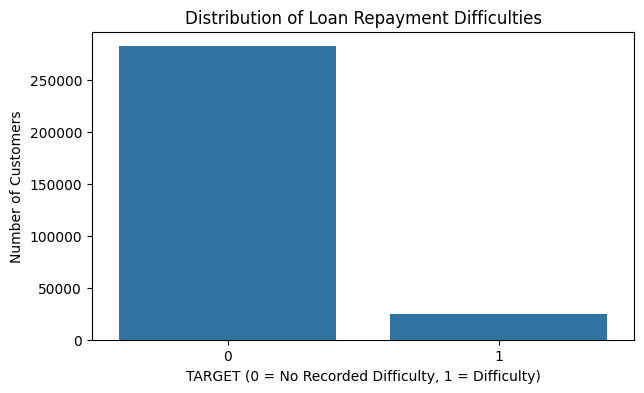

In [12]:
# TARGET ka graph

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="TARGET")

plt.title("Distribution of Loan Repayment Difficulties")
plt.xlabel("TARGET (0 = No Recorded Difficulty, 1 = Difficulty)")
plt.ylabel("Number of Customers")

plt.show()

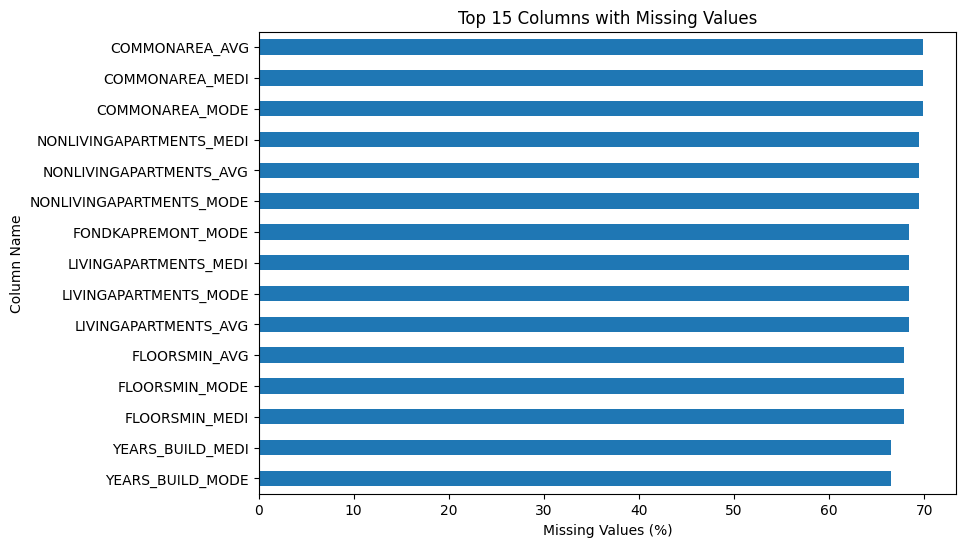

In [13]:
# Missing values ka graph

missing_percent.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 15 Columns with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Name")

plt.show()

In [14]:
df.dtypes.value_counts()

float64    65
int64      41
object     16
Name: count, dtype: int64

In [15]:
missing_percent.sort_values(ascending=True).head(20)

DAYS_LAST_PHONE_CHANGE         0.000325
CNT_FAM_MEMBERS                0.000650
AMT_ANNUITY                    0.003902
AMT_GOODS_PRICE                0.090403
EXT_SOURCE_2                   0.214626
OBS_30_CNT_SOCIAL_CIRCLE       0.332021
DEF_30_CNT_SOCIAL_CIRCLE       0.332021
DEF_60_CNT_SOCIAL_CIRCLE       0.332021
OBS_60_CNT_SOCIAL_CIRCLE       0.332021
NAME_TYPE_SUITE                0.420148
AMT_REQ_CREDIT_BUREAU_DAY     13.501631
AMT_REQ_CREDIT_BUREAU_MON     13.501631
AMT_REQ_CREDIT_BUREAU_QRT     13.501631
AMT_REQ_CREDIT_BUREAU_HOUR    13.501631
AMT_REQ_CREDIT_BUREAU_YEAR    13.501631
AMT_REQ_CREDIT_BUREAU_WEEK    13.501631
EXT_SOURCE_3                  19.825307
OCCUPATION_TYPE               31.345545
EMERGENCYSTATE_MODE           47.398304
TOTALAREA_MODE                48.268517
dtype: float64

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.groupby("TARGET")["AMT_INCOME_TOTAL"].mean()

TARGET
0    169077.722266
1    165611.760906
Name: AMT_INCOME_TOTAL, dtype: float64

In [18]:
# Features aur target alag karein

X = df.drop(columns=["TARGET", "SK_ID_CURR"])
y = df["TARGET"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (307511, 120)
Target: (307511,)


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_valid.shape)

Training data: (246008, 120)
Validation data: (61503, 120)


In [20]:
# identifing numerical & categorical column

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 104
Categorical columns: 16


In [21]:
# creating missing values pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical columns: median se missing values fill
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical columns: most frequent value se fill
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Dono pipelines ko combine karein
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [22]:
print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [23]:
# model creating 
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
# model train

model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


In [25]:
df.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

In [26]:
# # missing values fill preprocessing pipeline ke through karna bhi bilkul sahi hai. Isse validation data ki information training mein leak nahi hoti.

In [27]:
X_train_processed = model.named_steps["preprocessing"].transform(X_train)

print("Training data mein missing values:",
      np.isnan(X_train_processed).sum())

Training data mein missing values: 0


In [28]:
X_valid_processed = model.named_steps["preprocessing"].transform(X_valid)

print("Validation data mein missing values:",
      np.isnan(X_valid_processed).sum())

Validation data mein missing values: 0


In [29]:
# ROC-AUC score

from sklearn.metrics import roc_auc_score

y_valid_proba = model.predict_proba(X_valid)[:, 1]

roc_auc = roc_auc_score(y_valid, y_valid_proba)

print("Validation ROC-AUC:", round(roc_auc, 4))

Validation ROC-AUC: 0.7328


In [30]:
# Classification report
from sklearn.metrics import classification_report

y_valid_pred = model.predict(X_valid)

print(classification_report(y_valid, y_valid_pred))

              precision    recall  f1-score   support

           0       0.95      0.76      0.84     56538
           1       0.17      0.57      0.27      4965

    accuracy                           0.74     61503
   macro avg       0.56      0.67      0.56     61503
weighted avg       0.89      0.74      0.80     61503



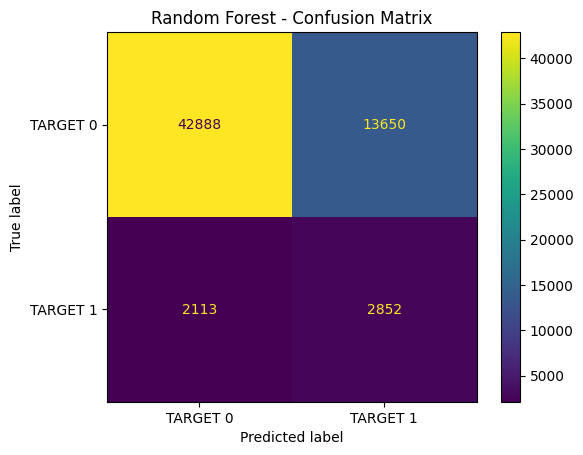

[[42888 13650]
 [ 2113  2852]]


In [31]:
# Confusion matrix banayein

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_valid, y_valid_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["TARGET 0", "TARGET 1"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

print(cm)

In [32]:
# Feature importance
# Kaun-se features prediction mein important hain, ye analyze karna.

# Get the trained Random Forest model
rf_model = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    model.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Show top 15 features
importance_df.head(15)

,Feature,Importance
29,num__EXT_SOURCE_3,0.149670
28,num__EXT_SOURCE_2,0.139291
27,num__EXT_SOURCE_1,0.060152
6,num__DAYS_BIRTH,0.039487
7,num__DAYS_EMPLOYED,0.030350
4,num__AMT_GOODS_PRICE,0.025629
77,num__DAYS_LAST_PHONE_CHANGE,0.023904
9,num__DAYS_ID_PUBLISH,0.020971
2,num__AMT_CREDIT,0.020282
129,cat__NAME_EDUCATION_TYPE_Higher education,0.017755


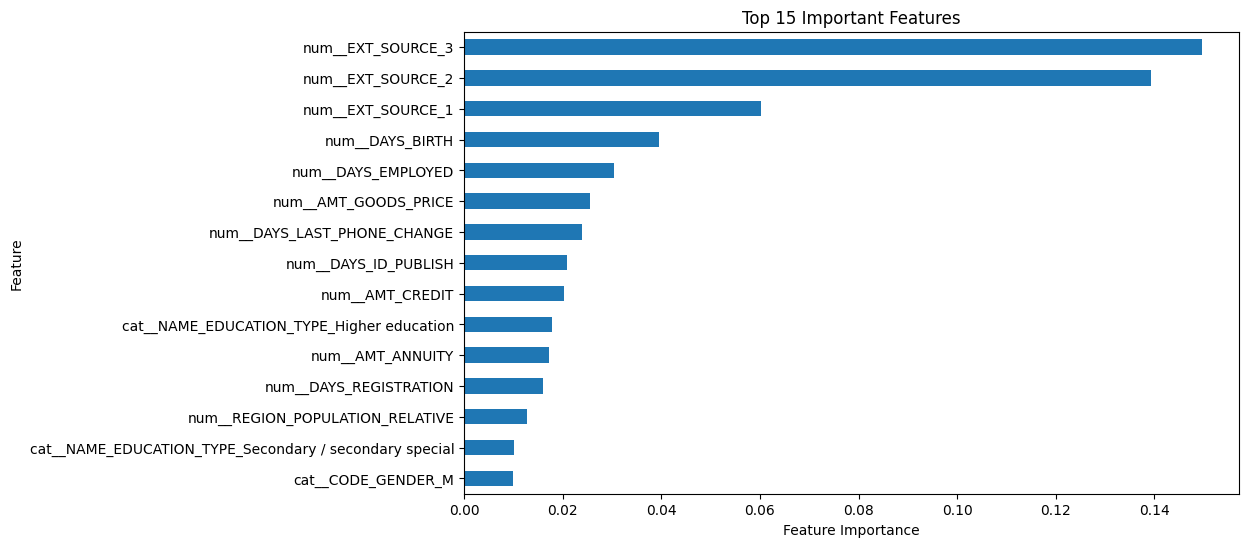

In [33]:
importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

In [34]:
# Doosra model — Logistic Regression( for comparision)

In [35]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical columns ki preprocessing
numeric_pipeline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns ki preprocessing
categorical_pipeline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Dono pipelines ko combine karna
preprocessor_lr = ColumnTransformer([
    ("num", numeric_pipeline_lr, numerical_cols),
    ("cat", categorical_pipeline_lr, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [36]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
# model train
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
# Validation ROC-AUC check karo
from sklearn.metrics import roc_auc_score

y_valid_proba_lr = logistic_model.predict_proba(X_valid)[:, 1]

roc_auc_lr = roc_auc_score(y_valid, y_valid_proba_lr)

print("Logistic Regression ROC-AUC:", round(roc_auc_lr, 4))

Logistic Regression ROC-AUC: 0.7487


In [39]:
# Classification Report
from sklearn.metrics import classification_report

y_valid_pred_lr = logistic_model.predict(X_valid)

print(classification_report(y_valid, y_valid_pred_lr))

              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.69      0.53     61503
weighted avg       0.90      0.69      0.76     61503



In [40]:
# Model Comparison
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "ROC-AUC": [0.7328, roc_auc_lr],
    "Defaulter Recall": [
        0.57,
        0.68
    ],
    "Defaulter Precision": [
        0.17,
        0.16
    ]
})

comparison

,Model,ROC-AUC,Defaulter Recall,Defaulter Precision
0,Random Forest,0.732800,0.57,0.17
1,Logistic Regression,0.748674,0.68,0.16


In [41]:
# Correct comparison table
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "ROC-AUC": [0.7328, roc_auc_lr],
    "Defaulter Recall": [0.57, 0.68],
    "Defaulter Precision": [0.17, 0.16]
})

comparison

,Model,ROC-AUC,Defaulter Recall,Defaulter Precision
0,Random Forest,0.732800,0.57,0.17
1,Logistic Regression,0.748674,0.68,0.16


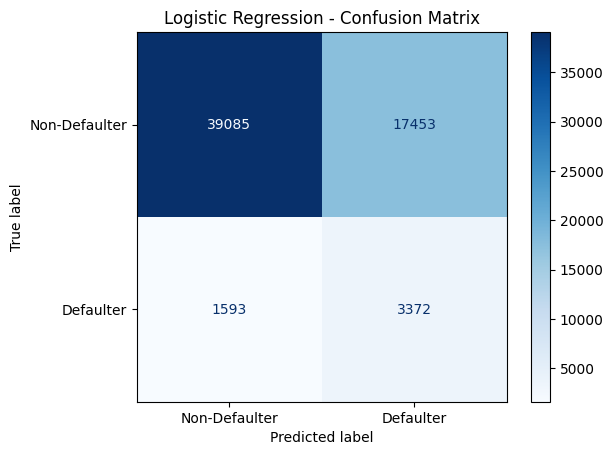

In [42]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_valid, y_valid_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Non-Defaulter", "Defaulter"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [43]:
# Random Forest vs Logistic Regression
# Ab dono models ki confusion matrix compare karne ke liye pehle Random Forest ke predictions se metrics nikaalte hain.

In [44]:
from sklearn.metrics import confusion_matrix

y_valid_pred_rf = model.predict(X_valid)

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_valid, y_valid_pred_rf))

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_valid, y_valid_pred_lr))

Random Forest Confusion Matrix:
[[42888 13650]
 [ 2113  2852]]

Logistic Regression Confusion Matrix:
[[39085 17453]
 [ 1593  3372]]


In [45]:
# Dono models ke defaulter probability scores
y_prob_rf = model.predict_proba(X_valid)[:, 1]
y_prob_lr = logistic_model.predict_proba(X_valid)[:, 1]

print("Random Forest ROC-AUC:", round(roc_auc_score(y_valid, y_prob_rf), 4))
print("Logistic Regression ROC-AUC:", round(roc_auc_score(y_valid, y_prob_lr), 4))

Random Forest ROC-AUC: 0.7328
Logistic Regression ROC-AUC: 0.7487


In [46]:
# Logistic Regression ke different thresholds compare karo
from sklearn.metrics import precision_score, recall_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    y_pred = (y_prob_lr >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Defaulter Precision": precision_score(y_valid, y_pred, zero_division=0),
        "Defaulter Recall": recall_score(y_valid, y_pred)
    })

threshold_results = pd.DataFrame(results)
threshold_results.round(3)

,Threshold,Defaulter Precision,Defaulter Recall
0,0.3,0.108,0.913
1,0.4,0.132,0.813
2,0.5,0.162,0.679
3,0.6,0.200,0.511
4,0.7,0.258,0.344


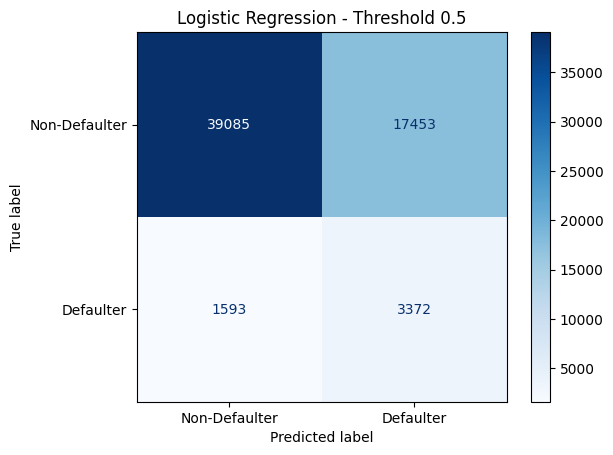

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

threshold = 0.5

y_pred_lr_05 = (y_prob_lr >= threshold).astype(int)

cm = confusion_matrix(y_valid, y_pred_lr_05)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Defaulter", "Defaulter"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Threshold 0.5")
plt.show()

In [48]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.3, 0.5]:
    y_pred = (y_prob_lr >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_valid, y_pred), 3))
    print("Recall:", round(recall_score(y_valid, y_pred), 3))


Threshold: 0.3
Precision: 0.108
Recall: 0.913

Threshold: 0.5
Precision: 0.162
Recall: 0.679


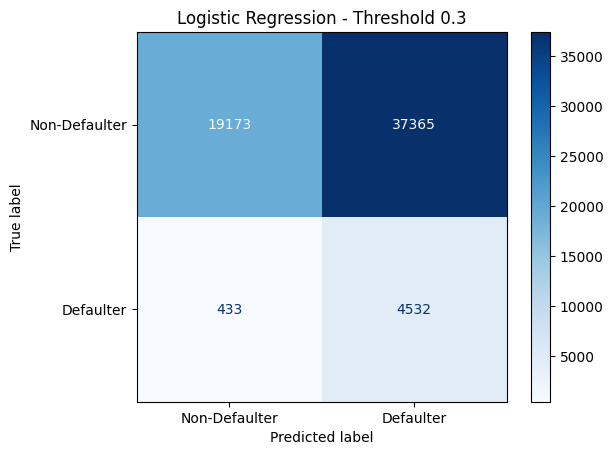

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

y_pred_lr_03 = (y_prob_lr >= 0.3).astype(int)

cm_03 = confusion_matrix(y_valid, y_pred_lr_03)

ConfusionMatrixDisplay(
    confusion_matrix=cm_03,
    display_labels=["Non-Defaulter", "Defaulter"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Threshold 0.3")
plt.show()

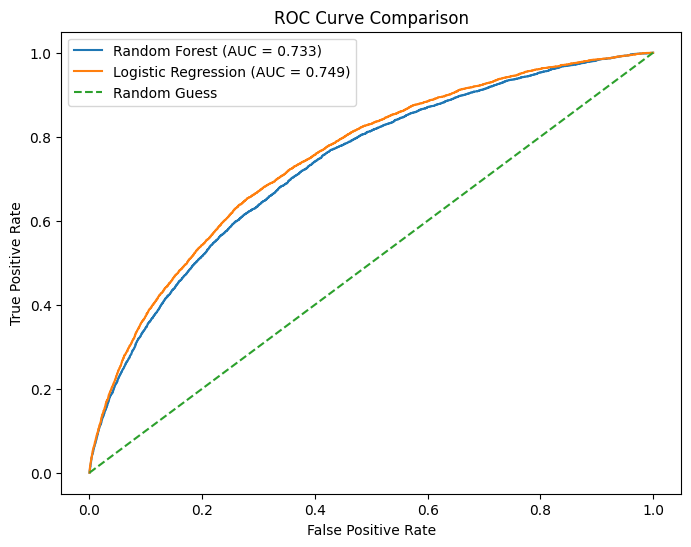

In [50]:
# ROC Curve Comparison
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_valid, y_prob_rf)
auc_rf = roc_auc_score(y_valid, y_prob_rf)

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_valid, y_prob_lr)
auc_lr = roc_auc_score(y_valid, y_prob_lr)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [51]:
# Final Model Comparison
final_comparison = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "ROC-AUC": [auc_rf, auc_lr],
    "Defaulter Recall": [0.574, 0.679],
    "Defaulter Precision": [0.173, 0.162]
})

final_comparison.round(3)

,Model,ROC-AUC,Defaulter Recall,Defaulter Precision
0,Random Forest,0.733,0.574,0.173
1,Logistic Regression,0.749,0.679,0.162


In [52]:
# Test Dataset

In [53]:
test_df = pd.read_csv("application_test.csv")

print("Test dataset shape:", test_df.shape)
test_df.head()

Test dataset shape: (48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [54]:
# Customer IDs save kar lo
test_ids = test_df["SK_ID_CURR"]

# Training jaise hi ID column hatao
X_test = test_df.drop(columns=["SK_ID_CURR"])

print("Test data shape:", X_test.shape)
print("Training features:", X_train.shape[1])
print("Test features:", X_test.shape[1])

Test data shape: (48744, 120)
Training features: 120
Test features: 120


In [55]:
# Naye Customers par Prediction
# Naye customers ke default hone ki probability
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Total predictions:", len(test_probabilities))
print("First 10 default probabilities:")
print(test_probabilities[:10])

Total predictions: 48744
First 10 default probabilities:
[0.40950813 0.76987268 0.34363378 0.28508838 0.61535796 0.23980568
 0.18373761 0.53481506 0.15101431 0.5707032 ]


In [56]:
# customer id ke sath probablity dekho
prediction_results = pd.DataFrame({
    "SK_ID_CURR": test_ids,
    "Default_Probability": test_probabilities
})

prediction_results.head(10)

,SK_ID_CURR,Default_Probability
0,100001,0.409508
1,100005,0.769873
2,100013,0.343634
3,100028,0.285088
4,100038,0.615358
5,100042,0.239806
6,100057,0.183738
7,100065,0.534815
8,100066,0.151014
9,100067,0.570703


In [57]:
# imaginary customer making

# Dataset ke pehle customer ko template banate hain
new_customer = X_test.iloc[[0]].copy()

# Example customer ki kuch values change karte hain
new_customer["AMT_INCOME_TOTAL"] = 360000
new_customer["AMT_CREDIT"] = 500000
new_customer["AMT_ANNUITY"] = 25000
new_customer["AMT_GOODS_PRICE"] = 450000
new_customer["DAYS_BIRTH"] = -10950  # 30 years
new_customer["DAYS_EMPLOYED"] = -1825  # 5 years employed

print("New customer created!")
new_customer[[
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]]


New customer created!


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED
0,360000,500000,25000,450000,-10950,-1825


In [58]:
# probablity check
# Naye customer ki Dono probabilities check karo
probabilities = logistic_model.predict_proba(new_customer)[0]

non_default_probability = probabilities[0] * 100
default_probability = probabilities[1] * 100

print("Non-Default Probability:",
      round(non_default_probability, 2), "%")

print("Default Probability:",
      round(default_probability, 2), "%")

Non-Default Probability: 60.76 %
Default Probability: 39.24 %


In [59]:
notebook_name = "Home_Credit_Default_Risk.ipynb"

print(f"Project notebook ka naam: {notebook_name}")

Project notebook ka naam: Home_Credit_Default_Risk.ipynb


In [60]:
import joblib

joblib.dump(logistic_model, "credit_risk_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [61]:
print(X_train.columns.tolist())

['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_

In [62]:
print(X_train.iloc[0].to_dict())

{'NAME_CONTRACT_TYPE': 'Cash loans', 'CODE_GENDER': 'F', 'FLAG_OWN_CAR': 'N', 'FLAG_OWN_REALTY': 'N', 'CNT_CHILDREN': 2, 'AMT_INCOME_TOTAL': 90000.0, 'AMT_CREDIT': 227520.0, 'AMT_ANNUITY': 13189.5, 'AMT_GOODS_PRICE': 180000.0, 'NAME_TYPE_SUITE': 'Unaccompanied', 'NAME_INCOME_TYPE': 'Commercial associate', 'NAME_EDUCATION_TYPE': 'Higher education', 'NAME_FAMILY_STATUS': 'Married', 'NAME_HOUSING_TYPE': 'House / apartment', 'REGION_POPULATION_RELATIVE': 0.00823, 'DAYS_BIRTH': -12298, 'DAYS_EMPLOYED': -946, 'DAYS_REGISTRATION': -6378.0, 'DAYS_ID_PUBLISH': -4670, 'OWN_CAR_AGE': nan, 'FLAG_MOBIL': 1, 'FLAG_EMP_PHONE': 1, 'FLAG_WORK_PHONE': 0, 'FLAG_CONT_MOBILE': 1, 'FLAG_PHONE': 0, 'FLAG_EMAIL': 0, 'OCCUPATION_TYPE': 'Laborers', 'CNT_FAM_MEMBERS': 4.0, 'REGION_RATING_CLIENT': 2, 'REGION_RATING_CLIENT_W_CITY': 2, 'WEEKDAY_APPR_PROCESS_START': 'WEDNESDAY', 'HOUR_APPR_PROCESS_START': 10, 'REG_REGION_NOT_LIVE_REGION': 0, 'REG_REGION_NOT_WORK_REGION': 0, 'LIVE_REGION_NOT_WORK_REGION': 0, 'REG_CIT

In [63]:
X_train.iloc[[0]].to_csv("reference_customer.csv", index=False)
print("Reference customer saved!")

Reference customer saved!
